# 10 — ColBERT-Extended Eval Harness: RAGAS Scoring

Scores every row in `eval_results_backend.jsonl` (written by `09_colbert_generation.ipynb`) with RAGAS, keyed the same way generation was: `(strategy, backend, id)`. Writes to `ragas_row_scores_backend.jsonl`.

Reuses the two load-bearing fixes from the dense-only scoring notebook, both still required here:

1. **Native top-level `await`, not `asyncio.run()` and not `nest_asyncio`.**    Both of those were confirmed broken on this project's Python 3.14    setup — `nest_asyncio` collides with `asyncio.timeout()`    (tracked upstream as Python 3.14-incompatible), and `asyncio.run()`    cannot be called from inside a cell that's already running inside    Jupyter's own event loop. The scoring loop below is an `async def`    awaited directly in a cell.
2. **`answer_relevancy.strictness = 1`** — RAGAS's `ResponseRelevancy`    metric asks the judge LLM for `n` completions per call (default 3);    Groq's API hard-caps `n` at 1. Ollama doesn't have this cap, but the    setting is harmless either way, so it stays on unconditionally.

**On the local Ollama path:** this notebook defaults to scoring with the local `qwen2.5:7b` model, matching what you'd already moved to for the dense-only run — flip `USE_LOCAL_OLLAMA` below if you'd rather burn Groq tokens instead.

In [ ]:
pip install matplotlib

In [1]:
%load_ext autoreload
%autoreload 2

import sys
import os
import json
import asyncio
import getpass
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))

if not os.environ.get('GROQ_API_KEY'):
    os.environ['GROQ_API_KEY'] = getpass.getpass("Enter Groq API Key: ")
if not os.environ.get('GOOGLE_API_KEY'):
    os.environ['GOOGLE_API_KEY'] = getpass.getpass("Enter Google API Key: ")

Enter Groq API Key:  ········
Enter Google API Key:  ········


## Judge LLM + embeddings

In [2]:
USE_LOCAL_OLLAMA = False  

from ragas.llms import LangchainLLMWrapper
from ragas.embeddings import LangchainEmbeddingsWrapper
from langchain_google_genai import GoogleGenerativeAIEmbeddings

if USE_LOCAL_OLLAMA:
    from langchain_ollama import ChatOllama
    OLLAMA_BASE_URL = "http://<ip-of-the-ollama-laptop>:11434"  # fill in
    judge_llm = ChatOllama(model="qwen2.5:7b", base_url=OLLAMA_BASE_URL, temperature=0)
else:
    from langchain_groq import ChatGroq
    judge_llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0)

ragas_llm = LangchainLLMWrapper(judge_llm)
ragas_embeddings = LangchainEmbeddingsWrapper(
    GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")
)
print(f"Judge LLM: {judge_llm}")

/home/mohnish/my-jupyter-env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Judge LLM: metadata={'lc_versions': {'langchain-core': '1.6.3', 'langchain': '1.3.17'}} profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True} client=<groq.resources.chat.completions.Completions object at 0x7f444d6441a0> async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x7f444d644c20> model_name='openai/gpt-oss-120b' temperature=1e-08 model_kwargs={} groq_api_key=SecretStr('**********')


/tmp/ipykernel_421037/1459063836.py:15: DeprecationWarning: LangchainLLMWrapper is deprecated and will be removed in a future version. Use llm_factory instead: from openai import OpenAI; from ragas.llms import llm_factory; llm = llm_factory('gpt-4o-mini', client=OpenAI(api_key='...'))
  ragas_llm = LangchainLLMWrapper(judge_llm)
/tmp/ipykernel_421037/1459063836.py:16: DeprecationWarning: LangchainEmbeddingsWrapper is deprecated and will be removed in a future version. Use the modern embedding providers instead: embedding_factory('openai', model='text-embedding-3-small', client=openai_client) or from ragas.embeddings import OpenAIEmbeddings, GoogleEmbeddings, HuggingFaceEmbeddings
  ragas_embeddings = LangchainEmbeddingsWrapper(


In [3]:
from ragas.metrics import faithfulness, answer_relevancy, context_precision, context_recall

for metric in (faithfulness, answer_relevancy, context_precision, context_recall):
    metric.llm = ragas_llm
    if hasattr(metric, "embeddings"):
        metric.embeddings = ragas_embeddings

answer_relevancy.strictness = 1  # Groq n>1 cap workaround; harmless on Ollama too

METRICS = {
    "faithfulness": faithfulness,
    "answer_relevancy": answer_relevancy,
    "context_precision": context_precision,
    "context_recall": context_recall,
}

/tmp/ipykernel_421037/3062966774.py:1: DeprecationWarning: Importing faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import faithfulness
  from ragas.metrics import faithfulness, answer_relevancy, context_precision, context_recall
/tmp/ipykernel_421037/3062966774.py:1: DeprecationWarning: Importing answer_relevancy from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import answer_relevancy
  from ragas.metrics import faithfulness, answer_relevancy, context_precision, context_recall
/tmp/ipykernel_421037/3062966774.py:1: DeprecationWarning: Importing context_precision from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import context_precision
  from ragas.metrics import fait

## Load generation results + scoring checkpoint

In [4]:
from rag_lab.utils import load_completed_keys, append_jsonl, call_with_backoff_async, is_daily_quota_error

EVAL_RESULTS_PATH = project_root / "eval" / "eval_results_backend.jsonl"
SCORES_PATH = project_root / "eval" / "ragas_row_scores_backend.jsonl"

rows = []
with open(EVAL_RESULTS_PATH) as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        row = json.loads(line)
        if row.get("answer") is not None:  # skip rows where generation itself failed
            rows.append(row)

print(f"{len(rows)} generated rows available to score")

scored_keys = load_completed_keys(
    SCORES_PATH,
    key_fields=("strategy", "backend", "id"),
    require_fields=("faithfulness", "answer_relevancy", "context_precision", "context_recall"),
)
print(f"{len(scored_keys)} rows already fully scored — will be skipped")

140 generated rows available to score
0 rows already fully scored — will be skipped


## Scoring loop

Per-metric, same as the dense-only run: each metric is scored independently so one metric's failure doesn't null out the other three for that row (`[PARTIAL]` rows carry whichever metrics did succeed).

In [6]:
from ragas.dataset_schema import SingleTurnSample

async def score_row_async(row):
    sample = SingleTurnSample(
        user_input=row["question"],
        response=row["answer"],
        retrieved_contexts=row["contexts"],
        reference=row.get("ground_truth"),
    )
    result = {"strategy": row["strategy"], "backend": row["backend"], "id": row["id"]}
    any_failed = False
    for name, metric in METRICS.items():
        try:
            score = await call_with_backoff_async(lambda m=metric: m.single_turn_ascore(sample))
            result[name] = score
        except Exception as e:
            print(f"  {row['strategy']}/{row['backend']}/{row['id']}/{name} failed: {e}")
            result[name] = None
            any_failed = True
            if is_daily_quota_error(e):
                result["_quota_exhausted"] = True
    result["partial"] = any_failed
    return result


async def run_scoring_loop_async(rows, scored_keys):
    quota_exhausted = False
    for row in rows:
        key = (row["strategy"], row["backend"], row["id"])
        if key in scored_keys:
            continue

        result = await score_row_async(row)
        quota_exhausted = result.pop("_quota_exhausted", False)
        append_jsonl(SCORES_PATH, result)
        scored_keys.add(key)
        tag = " [PARTIAL]" if result.get("partial") else ""
        print(f"scored {row['strategy']}/{row['backend']}/{row['id']}{tag}")

        if quota_exhausted:
            print("Hard daily-quota wall hit — stopping here. Rerun later to resume; "
                  "completed rows are checkpointed and will be skipped.")
            break
    return quota_exhausted

_ = await run_scoring_loop_async(rows, scored_keys)
print("Done." if not _ else "Stopped early on quota exhaustion.")

  naive/dense/b1_ntk_pinn_02/answer_relevancy failed: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01m1yxjkkve7a82nv5dyh8rra0` service tier `on_demand` on tokens per day (TPD): Limit 200000, Used 199106, Requested 1498. Please try again in 4m20.928s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}
  naive/dense/b1_ntk_pinn_02/context_precision failed: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01m1yxjkkve7a82nv5dyh8rra0` service tier `on_demand` on tokens per day (TPD): Limit 200000, Used 198863, Requested 4143. Please try again in 21m38.592s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}
  naive/dense/b1_ntk_pinn_02/context_recall failed: Error code: 429 - {'error'

## Dense vs ColBERT comparison

Mean of each RAGAS metric, per strategy, per backend — the number this whole extension exists to produce.

In [7]:
import pandas as pd

score_rows = []
with open(SCORES_PATH) as f:
    for line in f:
        line = line.strip()
        if line:
            score_rows.append(json.loads(line))

scores_df = pd.DataFrame(score_rows)
metric_cols = list(METRICS.keys())

summary = (
    scores_df
    .groupby(["strategy", "backend"])[metric_cols]
    .mean()
    .round(3)
)
summary

,,faithfulness,answer_relevancy,context_precision,context_recall
strategy,backend,,,,
naive,dense,0.917,NaN,NaN,NaN


Matplotlib is building the font cache; this may take a moment.


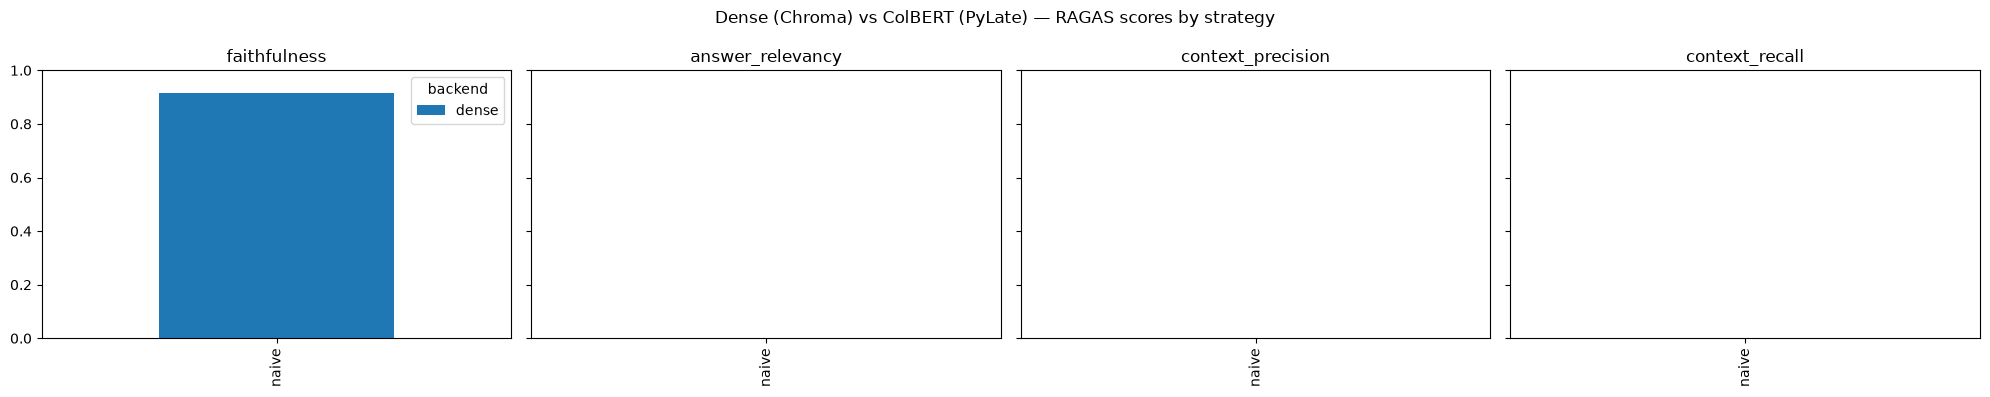

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(metric_cols), figsize=(5 * len(metric_cols), 4), sharey=True)

pivot_by_metric = {m: summary[m].unstack("backend") for m in metric_cols}

for ax, metric in zip(axes, metric_cols):
    pivot_by_metric[metric].plot(kind="bar", ax=ax, legend=(metric == metric_cols[0]))
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylim(0, 1)

fig.suptitle("Dense (Chroma) vs ColBERT (PyLate) — RAGAS scores by strategy")
fig.tight_layout()
plt.show()

## Reading this table

A few things worth checking once real numbers are in, rather than taking them at face value:

- **`context_precision` / `context_recall` validity depends on   `context_source`** from the generation notebook. Rows marked   `fallback_plain_retriever` for multi_query / rag_fusion / step_back /   decomposition are scoring against a retrieval call that may not match   what the strategy actually fed the LLM — worth cross-checking those   rows' `context_source` column in `eval_results_backend.jsonl` before   drawing conclusions about those specific strategies.
- **ColBERT's late-interaction scoring (`score` in   `ColBERTVectorStoreShim`'s metadata) is not the same scale as Chroma's   cosine similarity** — this comparison is about downstream RAGAS   metrics (which only see the retrieved *text*, not the retrieval   score), so the two backends are being compared on a fair, score-scale-  independent basis.
- If this was run against `eval_results.jsonl` (dense-only, pre-dedup)   instead of the fresh `eval_results_backend.jsonl` dense rows, the dense   column here would still be comparing against the corrupted 2131-chunk   corpus — this notebook only ever reads from `eval_results_backend.jsonl`,   so that's accounted for as long as 09 was actually re-run end to end.